[ 4.93479815 19.73914399 44.41289171]
[[ 249500.25  -124750.125      -0.    ...      -0.         -0.
       -0.   ]
 [-124750.125  249500.25  -124750.125 ...      -0.         -0.
       -0.   ]
 [     -0.    -124750.125  249500.25  ...      -0.         -0.
       -0.   ]
 ...
 [     -0.         -0.         -0.    ...  249500.25  -124750.125
       -0.   ]
 [     -0.         -0.         -0.    ... -124750.125  249500.25
  -124750.125]
 [     -0.         -0.         -0.    ...      -0.    -124750.125
   249500.25 ]]


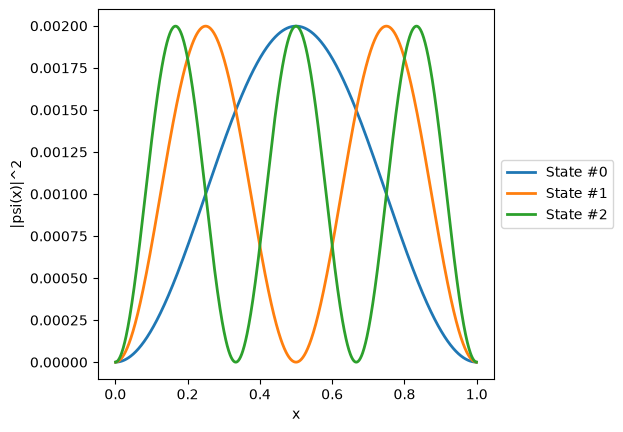

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def particle_in_a_box(L, N, nev=3):
    dx = L / (N + 1.0)
    x = np.linspace(dx, L - dx, N)
    
    main_diag = -2.0 * np.ones(N)
    off_diag = np.ones(N - 1)
    
    H = np.diag(main_diag) + np.diag(off_diag, k=-1) + np.diag(off_diag, k=1)
    H *= -0.5 / (dx * dx)
    
    
    all_E, all_psi = np.linalg.eigh(H)
    
    
    E = all_E[:nev]
    psi = all_psi[:, :nev]
    
    return E, psi, x

def particle_in_a_box_demo():
    E, psi, x = particle_in_a_box(1.0, 1000)

    print(E)
    print(H)

    
    fig = plt.figure()
    axs = plt.subplot(1, 1, 1)
    for n in range(len(E)):
        fig_label = "State #" + str(n)
        plt.plot(x, np.abs(psi[:, n])**2, label=fig_label, linewidth=2)
    plt.xlabel('x')
    plt.ylabel('|psi(x)|^2')

    box = axs.get_position()
    axs.set_position([box.x0, box.y0, box.width * 0.8, box.height])
    
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

particle_in_a_box_demo()


[ 4.93479815 19.73914399 44.41289171]
[[ 249500.25  -124750.125      -0.    ...      -0.         -0.
       -0.   ]
 [-124750.125  249500.25  -124750.125 ...      -0.         -0.
       -0.   ]
 [     -0.    -124750.125  249500.25  ...      -0.         -0.
       -0.   ]
 ...
 [     -0.         -0.         -0.    ...  249500.25  -124750.125
       -0.   ]
 [     -0.         -0.         -0.    ... -124750.125  249500.25
  -124750.125]
 [     -0.         -0.         -0.    ...      -0.    -124750.125
   249500.25 ]]


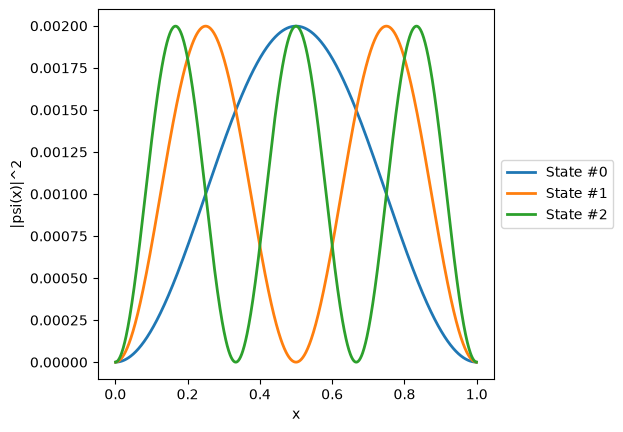

In [19]:
def integrate_schrodinger(E,L,N):
    dx = L/(N + 1.0)
    psi_interior = np.zeros(N)

    y1 = 0.0
    y2 = 1.0

    for i in range(N):
        k1_y1 = y2
        k1_y2 = -2.0 * E * y1

        k2_y1 = y2 + 0.5 * dx * k1_y2
        k2_y2 = -2.0 * E * (y1 + 0.5 * dx * k1_y1)

        k3_y1 = y2 + 0.5 * dx * k2_y2
        k3_y2 = -2.0 * E * (y1 + 0.5 * dx * k2_y1)

        k4_y1 = y2 + dx * k3_y2
        k4_y2 = -2.0 * E * (y1 + dx * k3_y1)

        y1 += (dx / 6.0) * (k1_y1 + 2.0 * k2_y1 + 2.0 * k3_y1 + k4_y1)
        y2 += (dx / 6.0) * (k1_y2 + 2.0 * k2_y2 + 2.0 * k3_y2 + k4_y2)

        psi_interior[i] = y1

        k1_y1 = y2
        k1_y2 = -2.0 * E * y1
        k2_y1 = y2 + 0.5 * dx * k1_y2
        k2_y2 = -2.0 * E * (y1 + 0.5 * dx * k1_y1)
        k3_y1 = y2 + 0.5 * dx * k2_y2
        k3_y2 = -2.0 * E * (y1 + 0.5 * dx * k2_y1)
        k4_y1 = y2 + dx * k3_y2
        k4_y2 = -2.0 * E * (y1 + dx * k3_y1)

        psi_L = y1 + (dx / 6.0) * (k1_y1 + 2.0 * k2_y1 + 2.0 * k3_y1 + k4_y1)
        return psi_interior, psi_L

    def shoot(E,L,N):
        psi_interior, psi_L = integrate_schrodinger(E,L,N)
        return psi_L

    def particle_in_a_box(L, N, nev=3):
        dx = L/(N + 1.0)
        x = np.linspace(dx, L - dx, N)

    E_eigenvalues = np.zeros(nev)
    psi_eigenstates = np.zeros((N, nev))

    E_search = 0.1
    dE = 0.2
    brackets = []
    f_old = shoot(E_search,L,N)

    while len(brackets) < nev:
        E_search += dE
        f_new = shoot(E_search,L,N)

        if f_old * f_new < 0:
            brackets.append((E_search - dE, E_search))

        f_old = f_new

        for n, (E_min, E_max) in enumerate(brackets):
            E_eigenvalue = (E_min + E_max) / 2.0
            for _ in range(100):
                f_mid = shoot(E_eigenvalue,L,N)
                if abs(f_mid) < 1e-6:
                    break
                if f_mid * shoot(E_min,L,N) < 0:
                    E_max = E_eigenvalue
                else:
                    E_min = E_eigenvalue
                E_eigenvalue = (E_min + E_max) / 2.0

            E_eigenvalues.append(E_eigenvalue)
            psi_int,_ = integrate_schrodinger(E_eigenvalue,L,N)
            psi_eigenstates[:,n] = psi_int

            return np.array(E_eigenvalues), psi_eigenstates, x

        def particle_in_a_box_demo():
                      E, psi, x = particle_in_a_box(1.0, 1000)

    print("Found energy eigenvalues:", E)

    fig = plt.figure()
    axs = plt.subplot(1,1,1)
    for n in range(len(E)):
        fig_label = "State #" + str(n)

        norm_psi = psi[:, n] / np.max(np.abs(psi[:, n]))
        plt.plot(x, np.abs(norm_psi)**2, label=fig_label, linewidth=2)
    plt.xlabel('x')
    plt.ylabel('|psi(x)|^2')

    box = axs.get_position()
    axs.set_position([box.x0, box.y0, box.width * 0.8, box.height])

    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

particle_in_a_box_demo()
